# Transaction patterns: worked analysis

> **Synthetic data - illustrative sample.** Every transaction here is generated by `src/generate_data.py` (seed 42). No real company or client data is used.

This notebook walks through the full pipeline: **clean → baseline → clusters → compare → charts**. All logic lives in `src/` and is imported here, so the notebook, the tests, the PNG/PDF charts and the web page all use the same code.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebook':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import config, narrative as nv
from src.clean import clean
from src.analysis import DetectionConfig, daily_series, detect_clusters, weekly_net, cluster_table
from src import charts_static

pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 90)

## 1. The raw export

The raw file is deliberately messy: three date formats, amounts stored as text (`"$1,234.50"`, signed values), the same transaction exported twice, blank categories, and inconsistent casing and labels.

In [2]:
raw = pd.read_csv(config.RAW_CSV, dtype=str, keep_default_na=False)
print(f'{len(raw):,} raw rows')
raw.sample(8, random_state=1)

11,230 raw rows


,transaction_id,date,amount,direction,category,counterparty
8950,TX007166,25/08/2025,1555.87,inflow,Customer receipts,Customer 26
8453,TX006994,2025-08-19,"$1,705.64",In,customer receipts,Customer 28
10897,TX010758,2025-12-24,"$1,556.44",credit,Customer receipts,CUSTOMER 08
7269,TX005756,2025-07-11,"$2,095.47",inflow,customer receipts,Customer 03
5518,TX009792,2025-11-22,572.69,out,Suppliers,Supplier E
2418,TX006130,23/07/2025,2195.42,IN,CUSTOMER RECEIPTS,CUSTOMER 04
8719,TX007194,2025-08-26,1786.98,credit,Customer receipts,Customer 01
3423,TX009857,2025-11-25,1457.32,in,Customer receipts,CUSTOMER 05


## 2. Cleaning, with a log of every fix

In [3]:
tx, log = clean(raw)
log.to_frame()

,step,detail,rows_affected
0,Load,Rows in raw export,11230
1,Trim whitespace,Leading/trailing spaces removed from text fields,3294
2,Standardise casing,Category/counterparty variants mapped to one spelling,6640
3,Normalise direction,Labels like IN / credit / outflow mapped to in/out,8967
4,Normalise dates,"Converted to ISO dates (ISO (2025-03-05): 6,646; UK day-first (05/03/2025): 2,923; Tex...",4584
5,Parse currency text,"Strings like ""$1,234.50"" converted to numbers",4418
6,Remove sign duplication,Negative amounts on outflows made positive (direction carries the sign),950
7,Remove duplicates,Repeated transaction IDs dropped (values identical after cleaning),220
8,Fill missing categories,Recovered from the counterparty's only known category,336
9,Flag unknown categories,"Left as ""Uncategorised""",0


Because the data is synthetic, we can check the result against the generator's ground truth:

In [4]:
truth = pd.read_csv(config.TRUTH_CSV, parse_dates=['date']).sort_values(['date', 'transaction_id']).reset_index(drop=True)
pd.testing.assert_frame_equal(tx, truth, check_dtype=False)
print('Cleaned data matches ground truth exactly.')

Cleaned data matches ground truth exactly.


## 3. Daily series and baseline

Detection uses **operating spend**, which excludes scheduled payroll and rent because those are known in advance. Each day is adjusted for its weekday. The baseline is a rolling median of the previous 28 days, and the spread is MAD × 1.4826. Days inside a detected cluster are taken out of the baseline and it is recalculated.

In [5]:
cfg = DetectionConfig()
cfg

DetectionConfig(window=28, spread_window=56, trailing=True, z_threshold=2.5, min_run=2, max_passes=5, n_boot=5000, seed=42)

In [6]:
daily = daily_series(tx)
daily, clusters = detect_clusters(daily, cfg)
daily[['outflow_operating', 'out_baseline', 'out_band_low', 'out_band_high', 'out_z', 'out_flagged']].loc['2025-03-07':'2025-03-17'].round(2)

,outflow_operating,out_baseline,out_band_low,out_band_high,out_z,out_flagged
date,,,,,,
2025-03-07,9185.93,8914.60,6458.58,11370.62,-0.27,False
2025-03-08,5290.35,8914.60,6586.12,11243.08,-0.07,False
2025-03-09,4580.06,8914.60,6713.67,11115.53,-0.12,False
2025-03-10,5908.36,8780.52,6585.12,10975.92,-1.75,False
2025-03-11,36004.01,8687.10,6486.17,10888.03,8.42,True
2025-03-12,34729.12,8741.74,6540.81,10942.67,10.13,True
2025-03-13,30739.06,8687.10,6358.62,11015.57,9.13,True
2025-03-14,9195.72,8632.46,6431.53,10833.39,-0.16,False
2025-03-15,5054.41,8632.46,6431.53,10833.39,-0.12,False


## 4. Detected clusters vs planted anomalies

In [7]:
planted = pd.DataFrame(json.loads(config.PLANTED_JSON.read_text()))[['id', 'kind', 'category', 'start', 'end']]
detected = pd.DataFrame([{'kind': c.kind, 'start': c.start.date(), 'end': c.end.date(), 'days': c.n_days} for c in clusters])
display(planted)
display(detected)

,id,kind,category,start,end
0,A,spend_cluster,Equipment,2025-03-11,2025-03-13
1,B,spend_cluster,Contractors,2025-08-11,2025-08-15
2,C,inflow_drought,Customer receipts,2025-10-14,2025-10-19


,kind,start,end,days
0,spend_cluster,2025-03-11,2025-03-13,3
1,spend_cluster,2025-08-11,2025-08-15,5
2,inflow_drought,2025-10-14,2025-10-19,6


## 5. How unusual is each cluster?

Each cluster is compared with every other window of the same length that doesn't touch a cluster. The percentile is **descriptive** (the share of normal windows it beats), not a p-value. The 95% interval is a bootstrap of the cluster's own days.

In [8]:
cluster_table(clusters)

,period,type,days,total ($),"mean per day, adj. ($)",typical per day ($),x typical,95% CI per day ($),compared with normal periods
0,Mar 11-13,Spend cluster,3,101472,28423,9779,2.91,"25,884 - 29,990",Higher than all 351 normal 3-day periods
1,Aug 11-15,Spend cluster,5,108671,18506,9731,1.90,"17,417 - 19,470",Higher than all 345 normal 5-day periods
2,Oct 14-19,Inflow drought,6,13776,2608,19063,0.14,"777 - 4,563",Lower than all 349 normal 6-day periods


### Sensitivity: what if the threshold were stricter or looser?

In [9]:
rows = []
for z in (2.0, 2.5, 3.0, 3.5):
    for run in (2, 3):
        _, cl = detect_clusters(daily_series(tx), DetectionConfig(z_threshold=z, min_run=run))
        rows.append({'z threshold': z, 'min run': run, 'clusters': len(cl),
                     'periods': ', '.join(c.label for c in cl)})
pd.DataFrame(rows)

,z threshold,min run,clusters,periods
0,2.0,2,6,"Mar 11-13, Apr 23-24, May 28-29, Aug 10-15, Sep 8-9, Oct 14-19"
1,2.0,3,3,"Mar 11-13, Aug 10-15, Oct 14-19"
2,2.5,2,3,"Mar 11-13, Aug 11-15, Oct 14-19"
3,2.5,3,3,"Mar 11-13, Aug 11-15, Oct 14-19"
4,3.0,2,3,"Mar 11-13, Aug 11-15, Oct 14-19"
5,3.0,3,3,"Mar 11-13, Aug 11-15, Oct 14-19"
6,3.5,2,3,"Mar 11-13, Aug 13-14, Oct 14-18"
7,3.5,3,2,"Mar 11-13, Oct 14-18"


### Robustness on data the method was not tuned on

`src/robustness.py` regenerates the ledger with 30 other seeds (same planted anomalies, different noise) and scores the detector at default settings.

In [10]:
rob = json.loads((config.DATA_DIR / 'robustness.json').read_text())
{k: v for k, v in rob.items() if k != 'rows'}

{'n_seeds': 30,
 'planted_total': 90,
 'found': 89,
 'found_within_1_day': 80,
 'false_clusters': 5,
 'seeds_with_false_clusters': 5}

## 6. Charts

The same functions write the 300 dpi PNG and vector PDF files in `outputs/`.

In [11]:
from src.analysis import Results
r = Results(tx, log, daily, weekly_net(daily), clusters, cfg)
paths = charts_static.build_all(r)
for name, (png, pdf) in paths.items():
    print(png.relative_to(config.ROOT), '|', pdf.relative_to(config.ROOT))

outputs/png/1_spending_velocity.png | outputs/pdf/1_spending_velocity.pdf
outputs/png/2_cash_flow.png | outputs/pdf/2_cash_flow.pdf
outputs/png/3_cluster_vs_normal.png | outputs/pdf/3_cluster_vs_normal.pdf


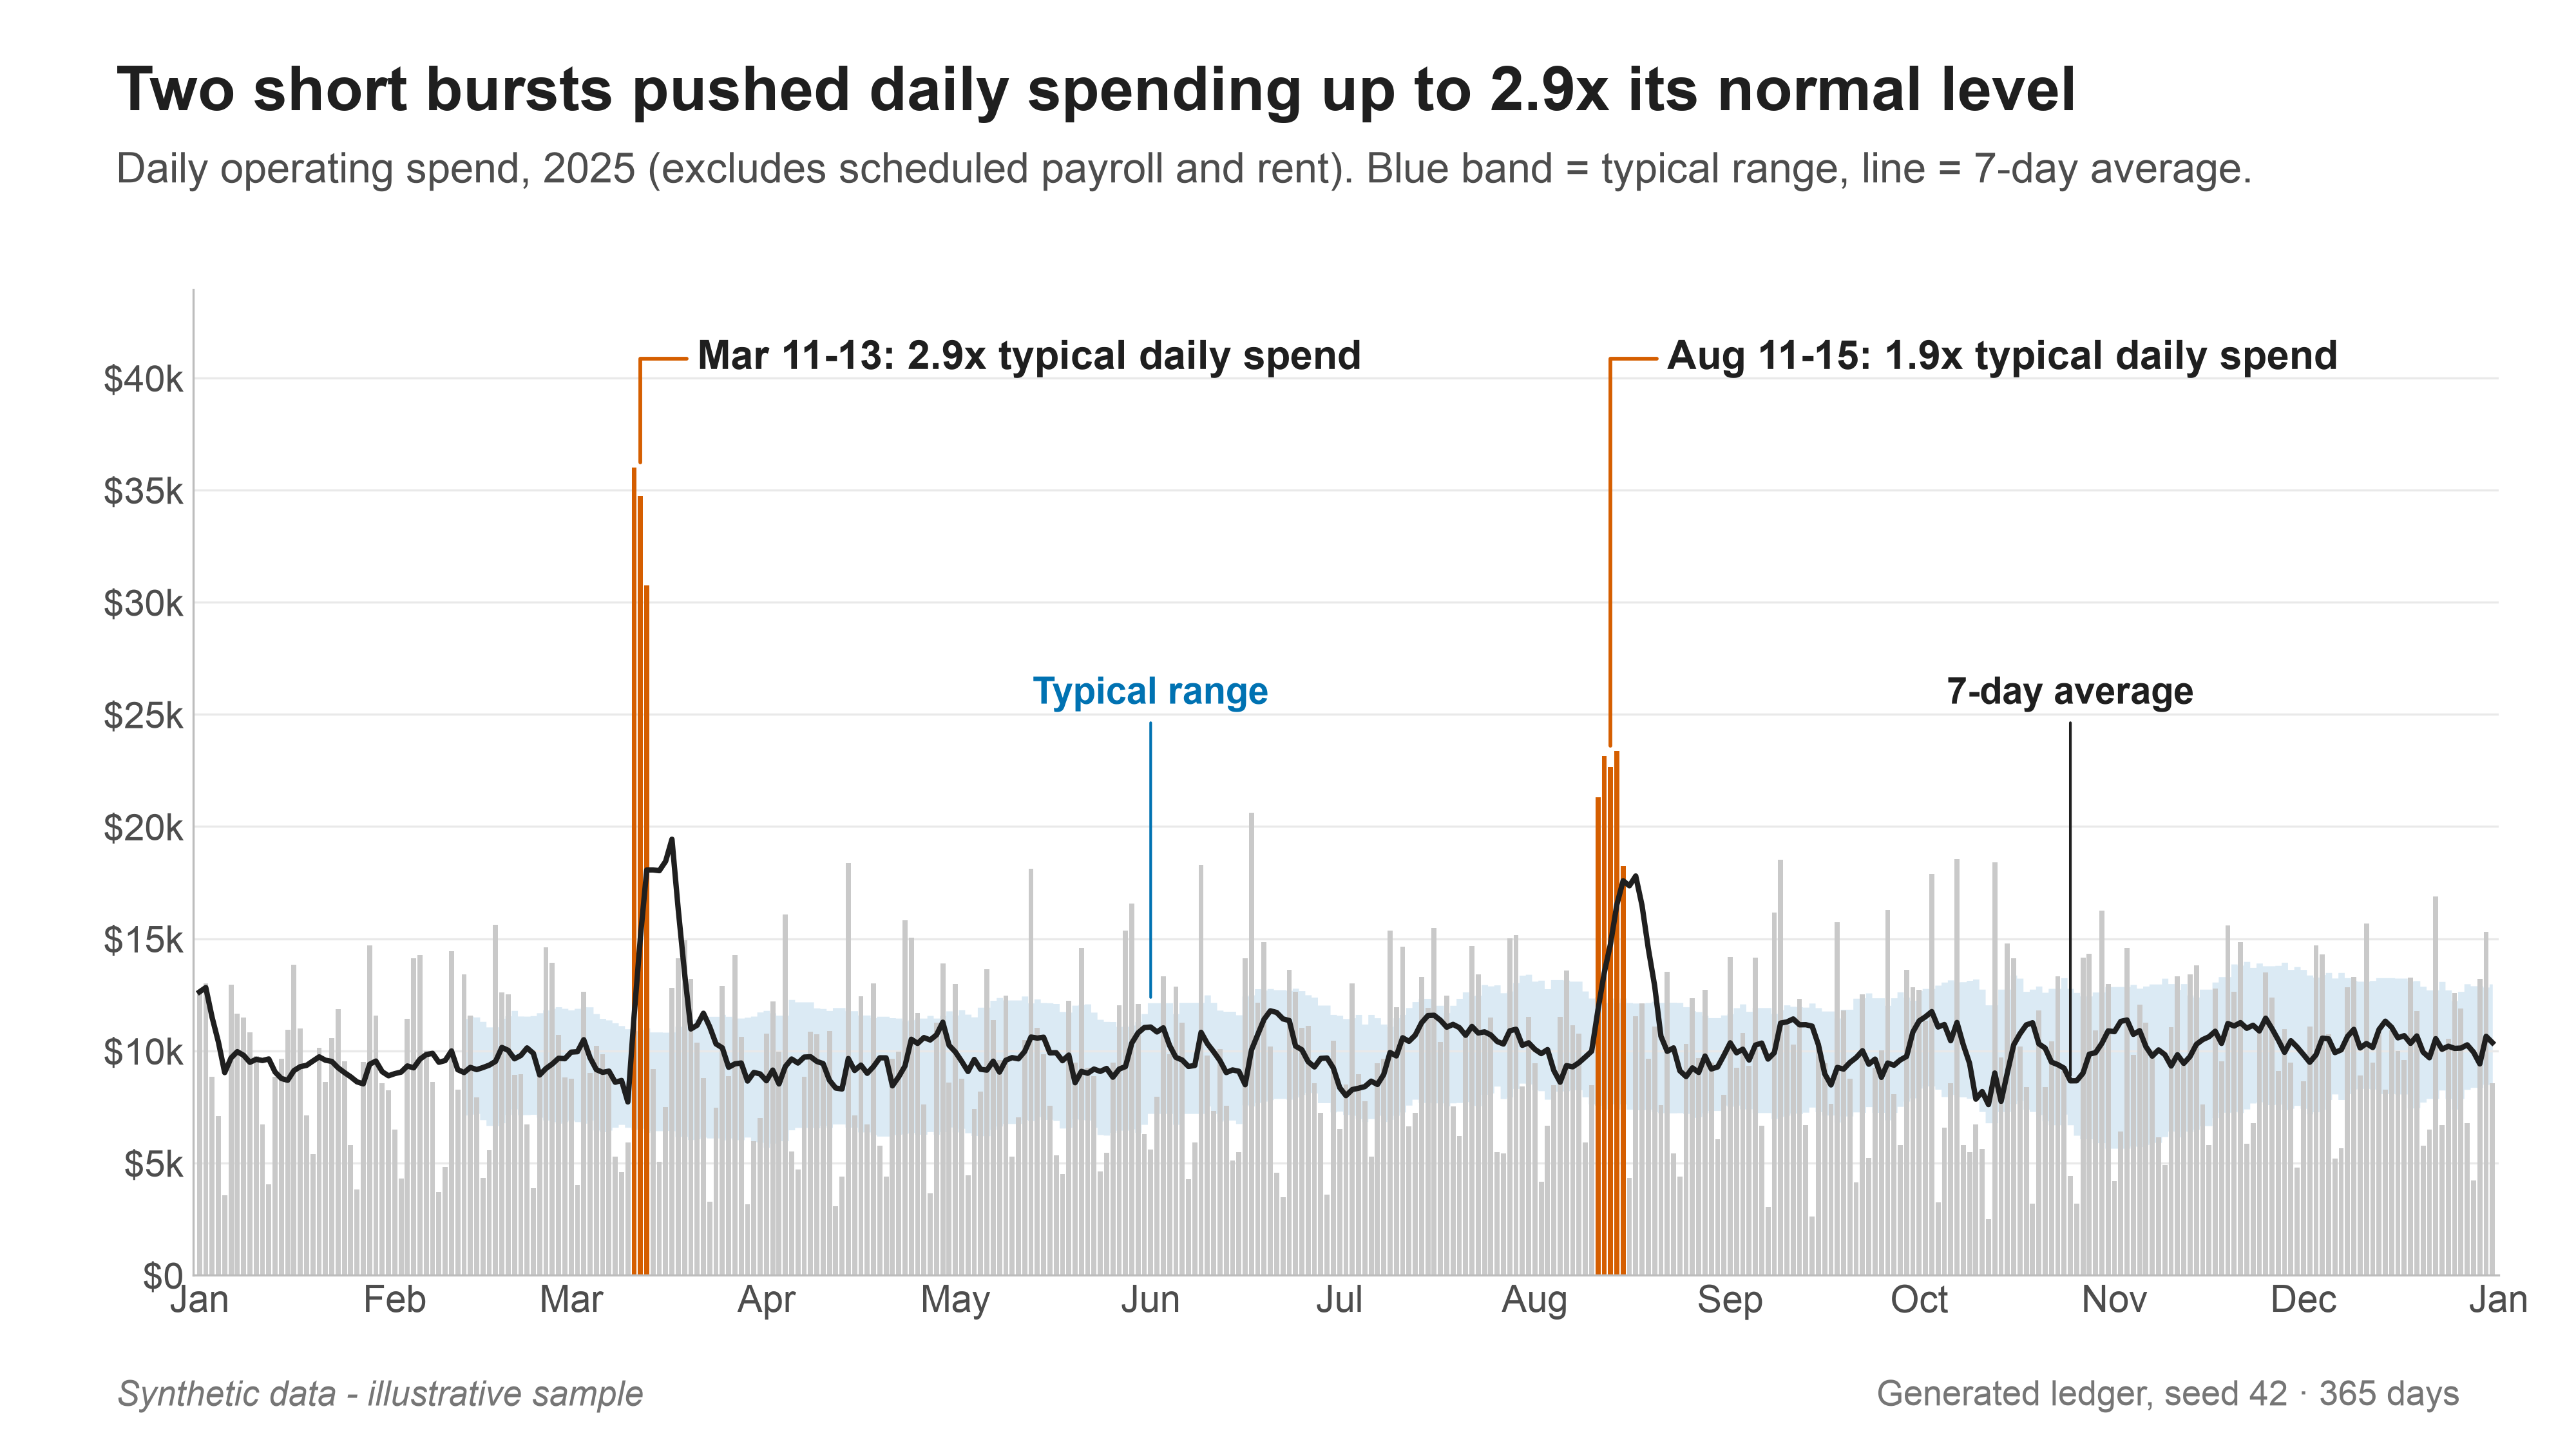

On a normal day the business spends about $10k on operations, and that level moved +14% between Q1 and Q4. Two periods break clearly away from that baseline: Mar 11-13 (3 days, $101k in total, 2.9x typical) and Aug 11-15 (5 days, $109k in total, 1.9x typical). Each was driven by one category (Equipment in March, Contractors in August), so each can be checked quickly against approvals or purchase orders.


In [12]:
display(Image(filename=str(paths['1_spending_velocity'][0]), width=900))
print(nv.velocity_insight(r))

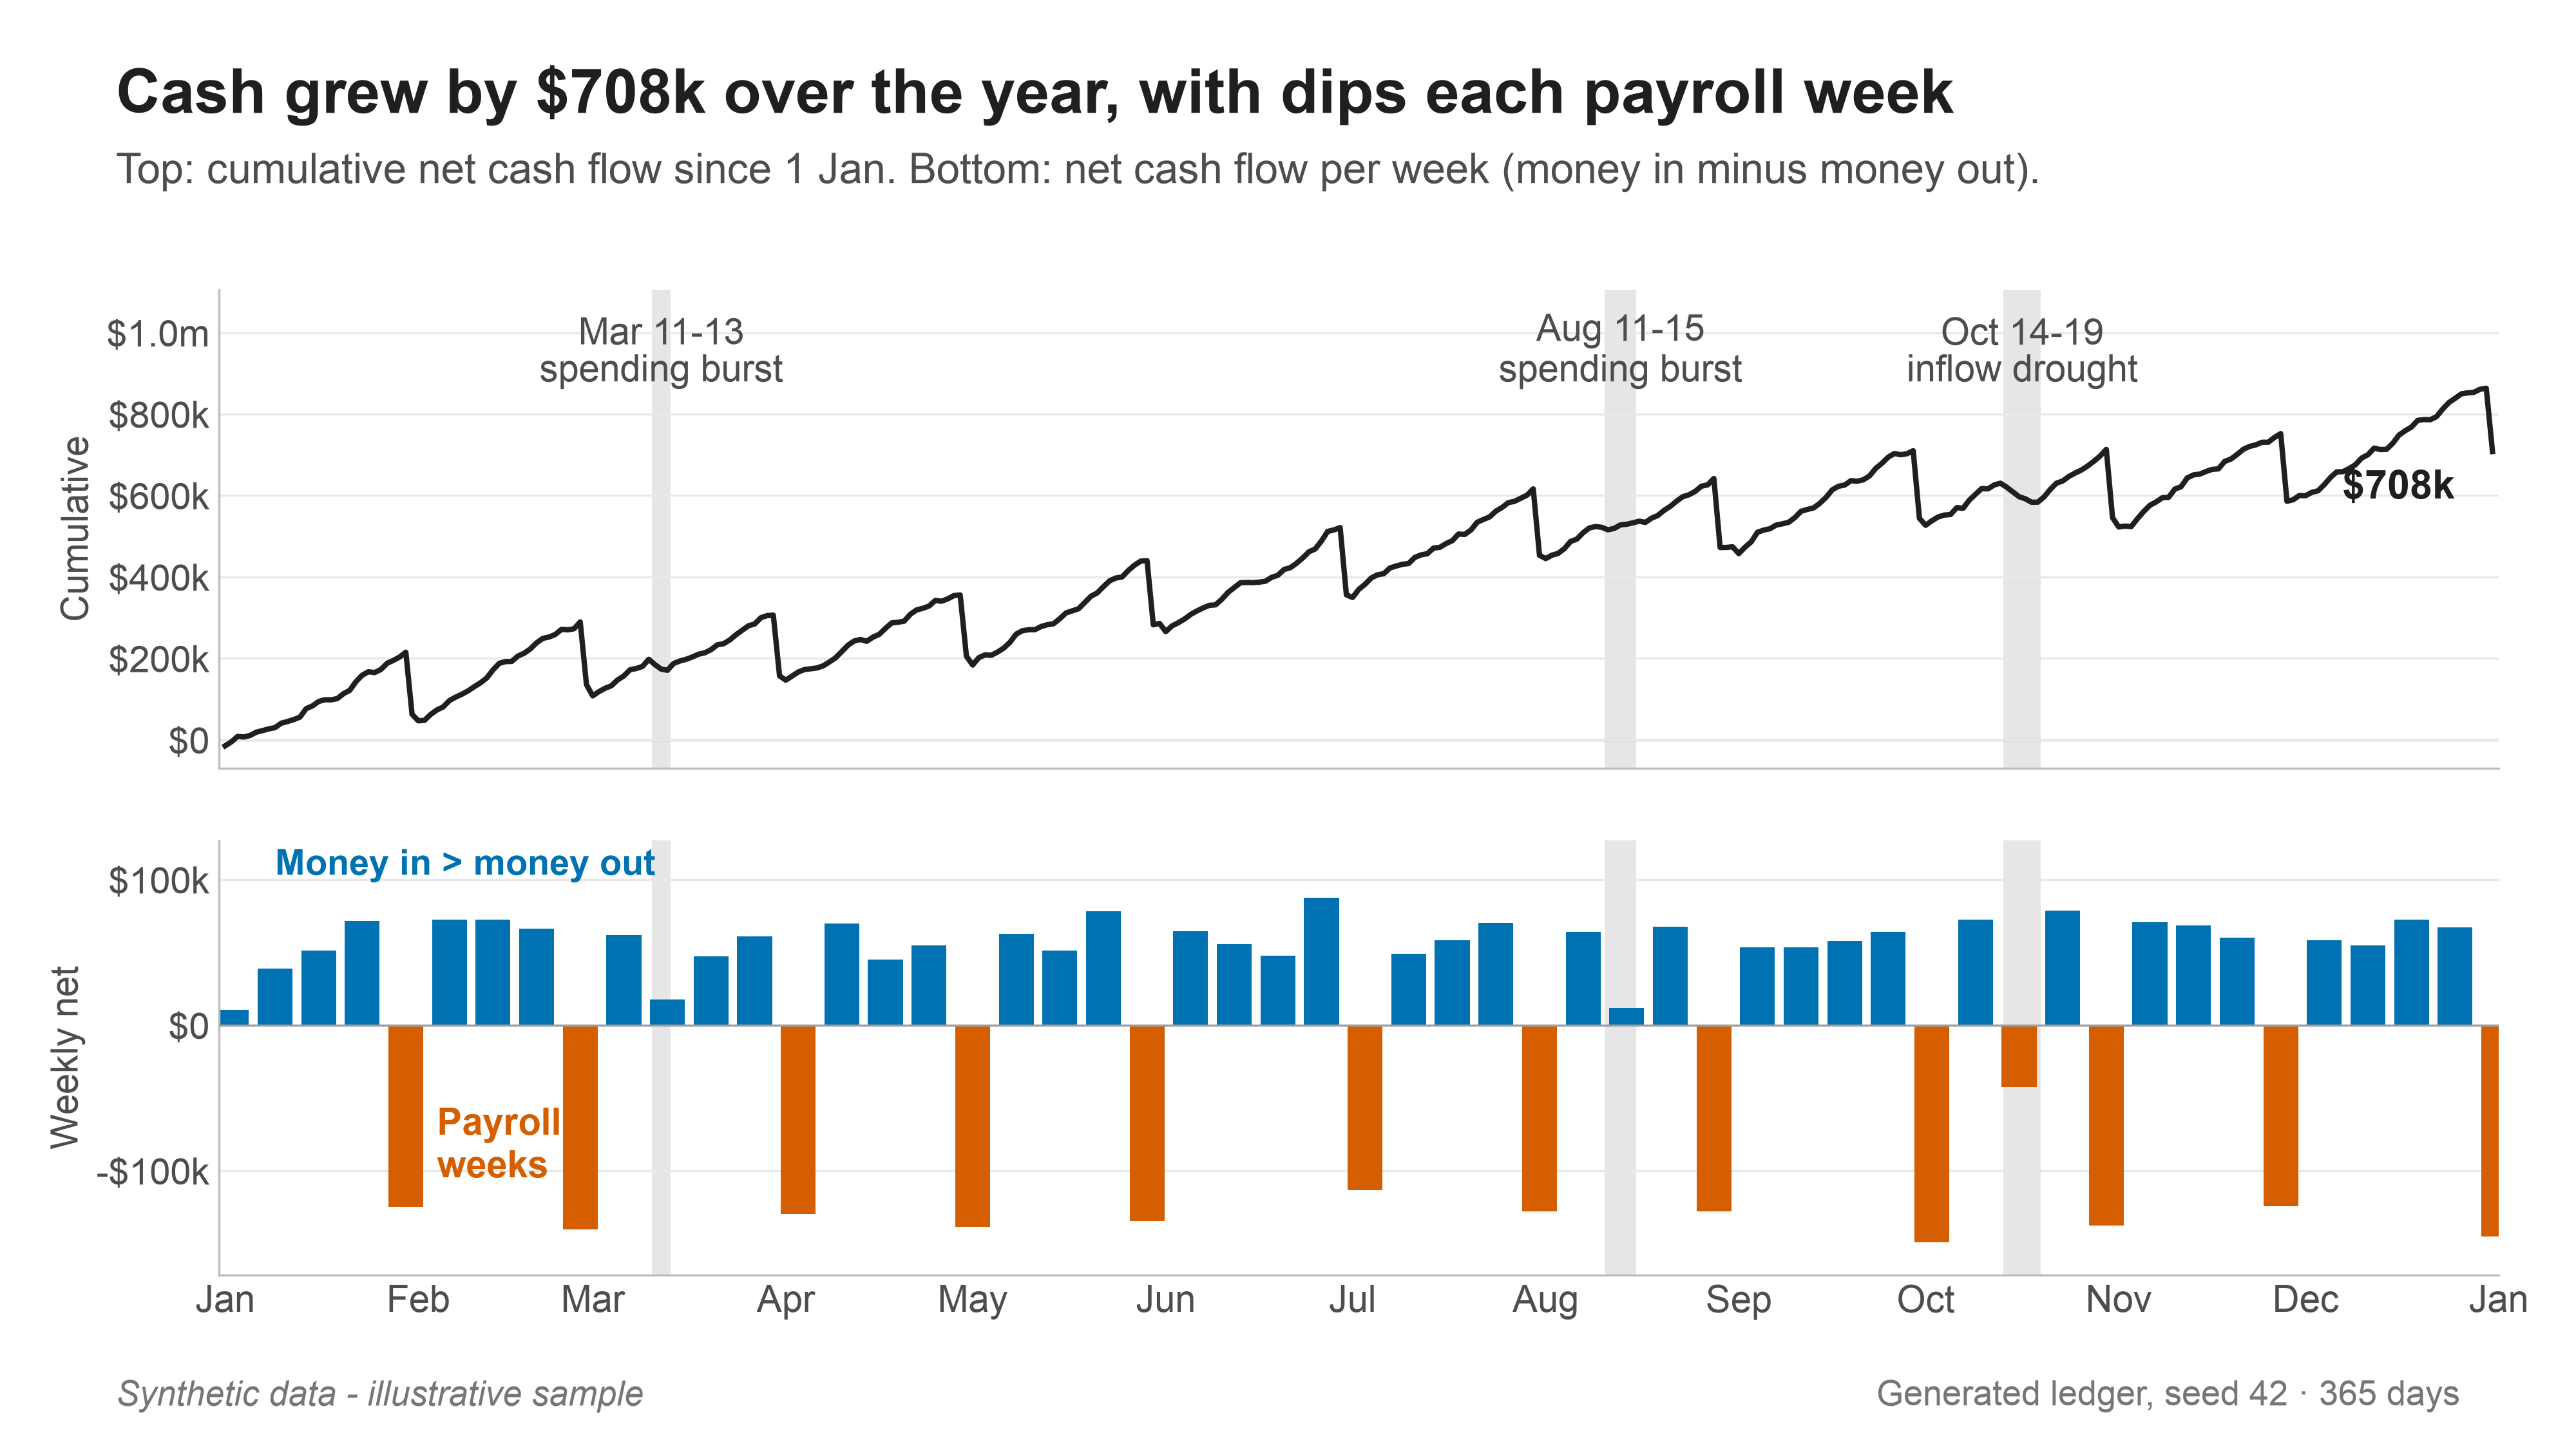

Money in exceeded money out by $708k across 2025. The 12 negative weeks that line up with month-end payroll are expected and recover within days. Only 1 other week went negative (week of 13 Oct: -$42k), caused by the Oct 14-19 inflow drought. The spending bursts did not push any week below zero, but they cut those weeks' net inflow by at least 72% compared with a normal week.


In [13]:
display(Image(filename=str(paths['2_cash_flow'][0]), width=900))
print(nv.cashflow_insight(r))

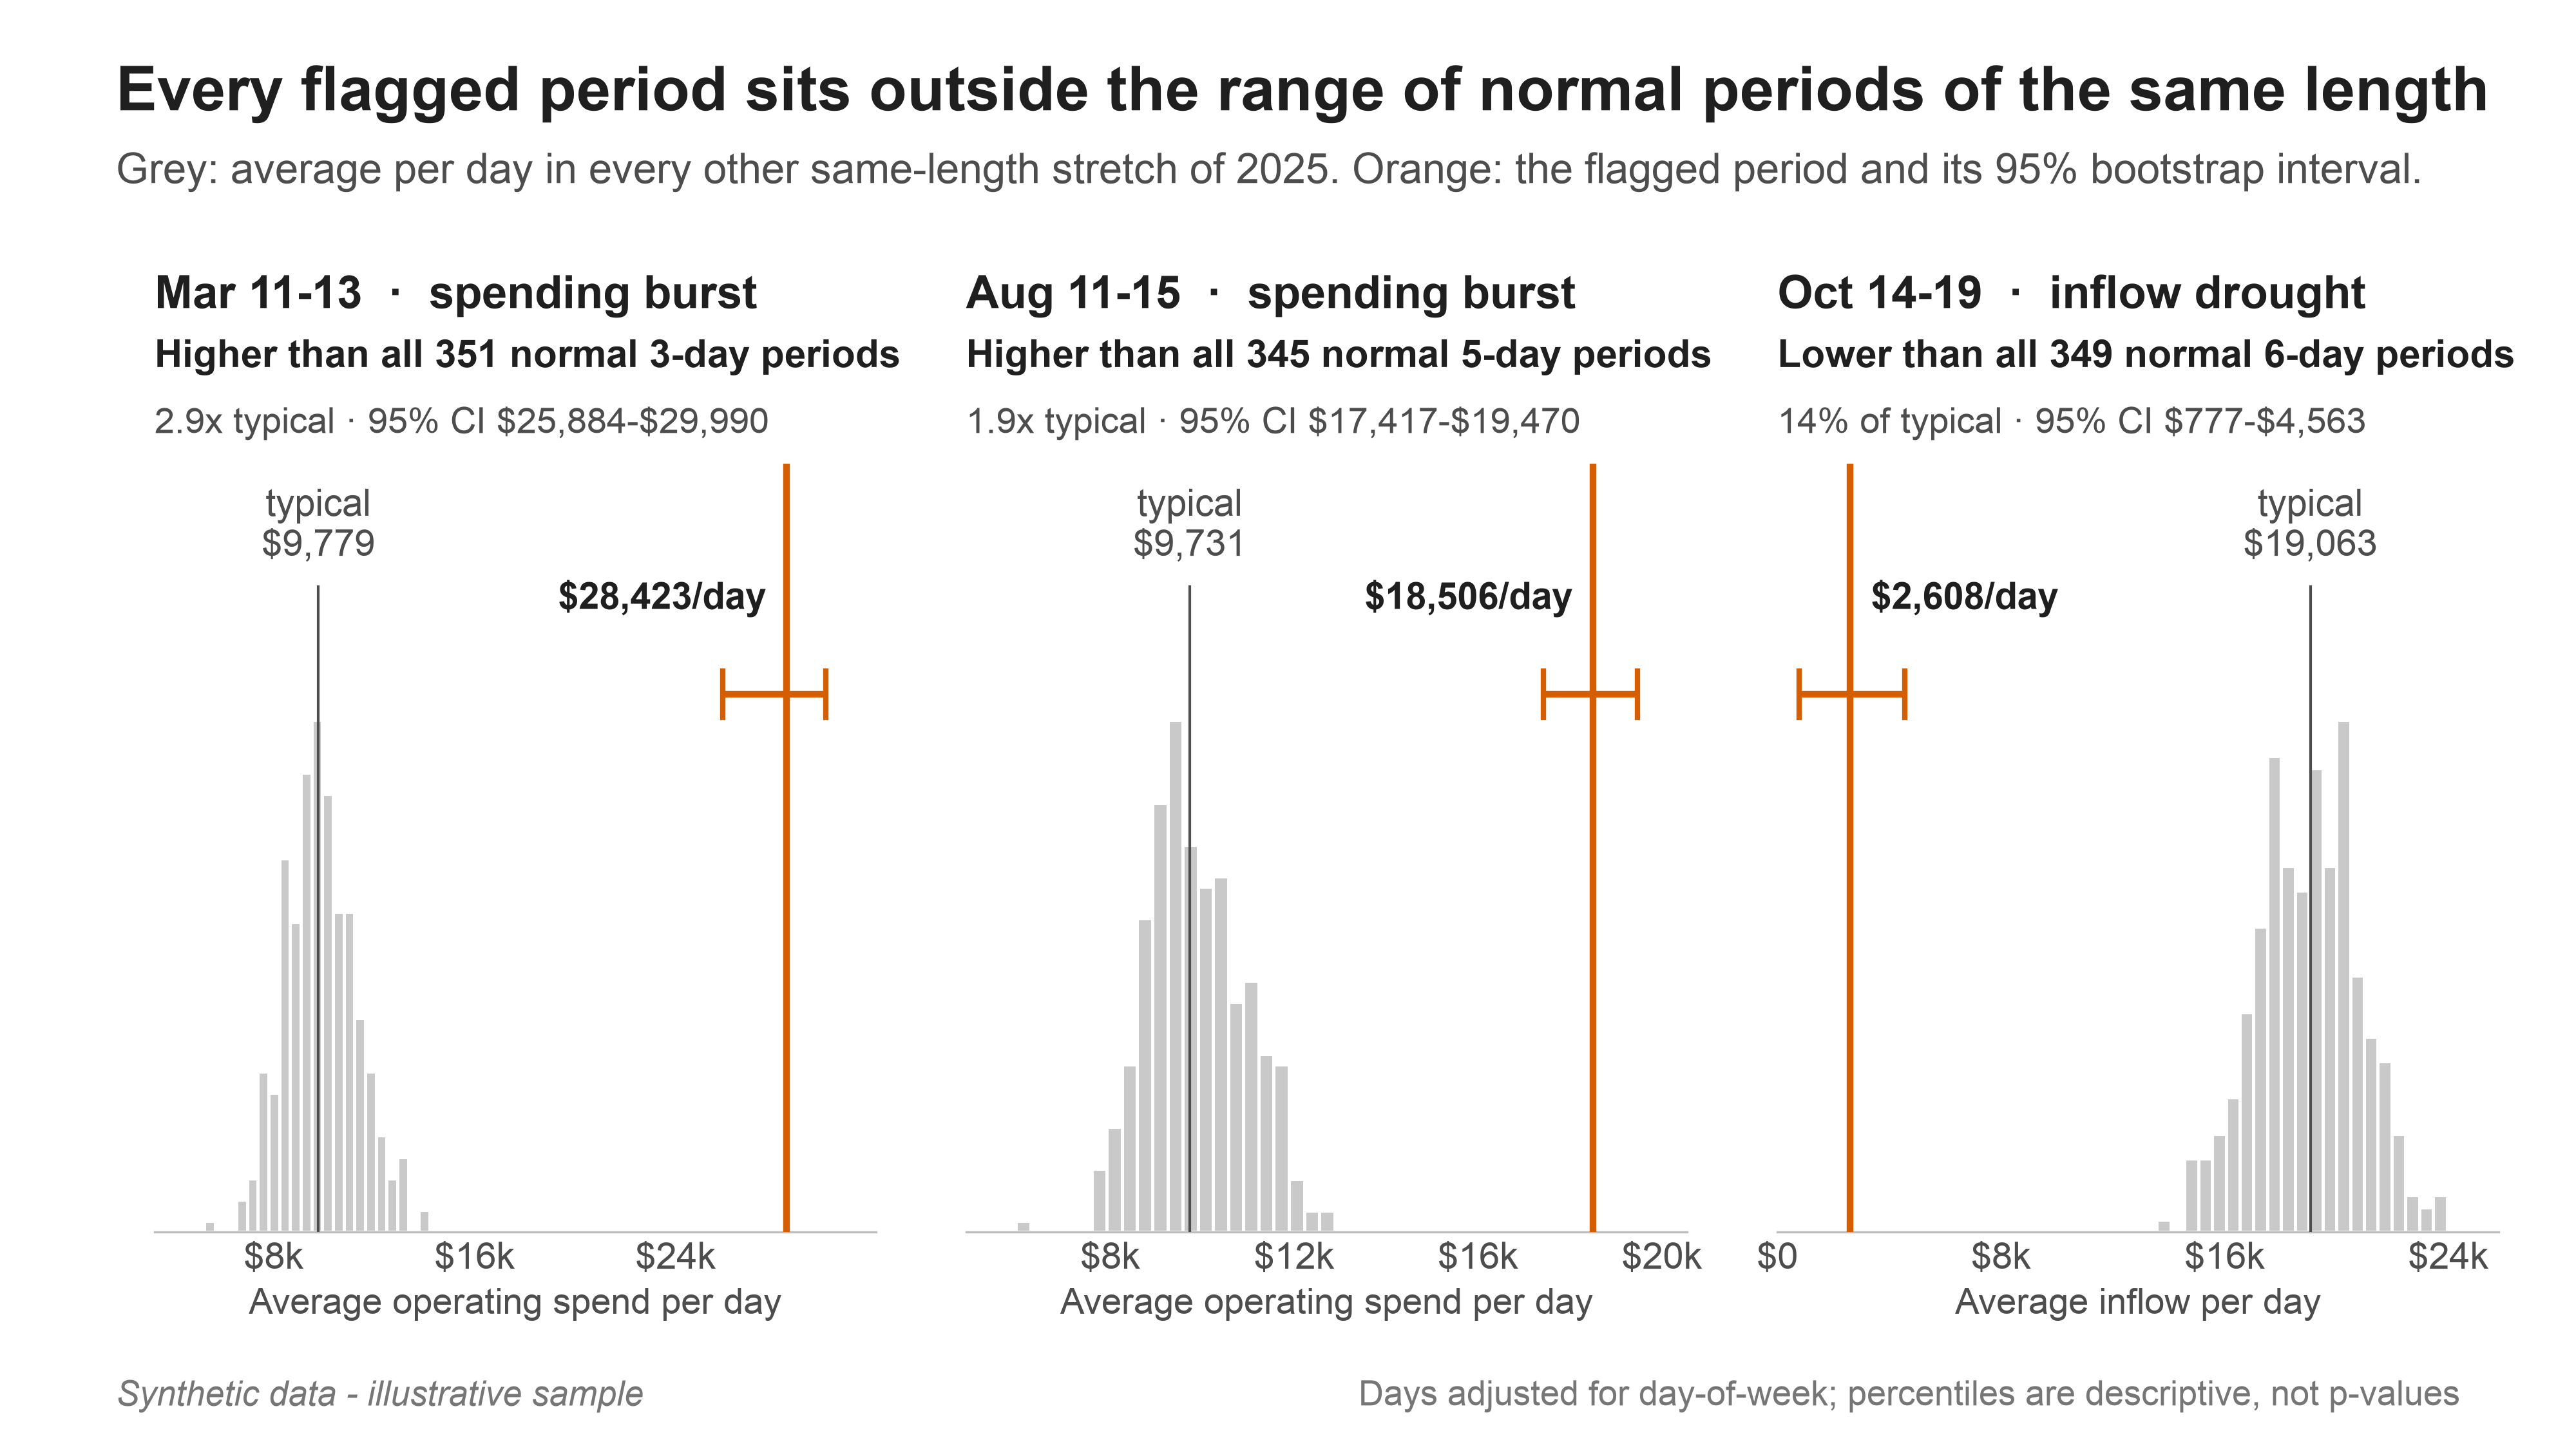

Each panel compares one flagged period with at least 345 ordinary stretches of the same length from the same year. None of those ordinary stretches reached the flagged level, so these are not just a run of busy or quiet days. The percentages describe where a period sits among normal periods; they are not significance tests.


In [14]:
display(Image(filename=str(paths['3_cluster_vs_normal'][0]), width=900))
print(nv.compare_insight(r))

## 7. Limitations

- The data is synthetic. Real ledgers have quirks this one lacks, such as quarter-ends, bank holidays and reversals.
- The baseline needs about four weeks of history, so early January is not scored.
- Short clusters give rough bootstrap intervals.
- Windows overlap, so the reference periods aren't independent. This is another reason the percentiles are descriptive only.
- A flag means *look here*, not *something is wrong*.